In [42]:
import pandas as pd
import numpy as np
import yfinance as yf
import datetime as dt
import scipy.stats as sci
import matplotlib.pyplot as plt

In [14]:
def get_data(stocks, period='1Y'):
    close_prices=yf.Tickers(stocks).download(period=period)['Close']
    returns=close_prices.pct_change()
    mean_returns=returns.mean()
    cov_matrx=returns.cov()
    return mean_returns, cov_matrx

In [6]:
def get_stocks(file):
    with open(file) as f:
        stocks = [line.strip() for line in f]
        
    return stocks


In [9]:
tstocks = get_stocks('cashapp.txt')

In [20]:
tstocks[-5:]

['META', 'AMZN', 'GOOGL', 'AAPL', 'NVDA']

In [22]:
mean_ret, cov_mat=get_data(tstocks[:5])

print(mean_ret)
print(cov_mat)

[*********************100%***********************]  4 of 5 completed


Ticker
ARRY   -0.000319
CL      0.000510
GEHC    0.000271
TTWO    0.000448
WMG    -0.000620
dtype: float64
Ticker      ARRY        CL      GEHC      TTWO       WMG
Ticker                                                  
ARRY    0.002525 -0.000086  0.000060  0.000013 -0.000076
CL     -0.000086  0.000202  0.000073 -0.000042  0.000069
GEHC    0.000060  0.000073  0.000495  0.000037  0.000122
TTWO    0.000013 -0.000042  0.000037  0.000404  0.000086
WMG    -0.000076  0.000069  0.000122  0.000086  0.000466


C:\Users\USER\AppData\Local\Temp\ipykernel_2492\53146773.py:3: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns=close_prices.pct_change()


In [36]:
weights=np.random.random(len(mean_ret))
weights /= np.sum(weights)

In [41]:
numb_sim=100
T=100

meanM=np.full(shape=(T, len(weights)), fill_value=mean_ret)
meanM=meanM.T

portfolio_sims=np.full(shape=(T, numb_sim), fill_value=0.0)


In [44]:
init_port=10000

for m in range(0, numb_sim):
    Z=np.random.normal(size=(T, len(weights)))
    L=np.linalg.cholesky(cov_mat)
    daily_ret=meanM + np.inner(L, Z)
    portfolio_sims[:,m]=np.cumprod(np.inner(weights, daily_ret.T)+1)*init_port

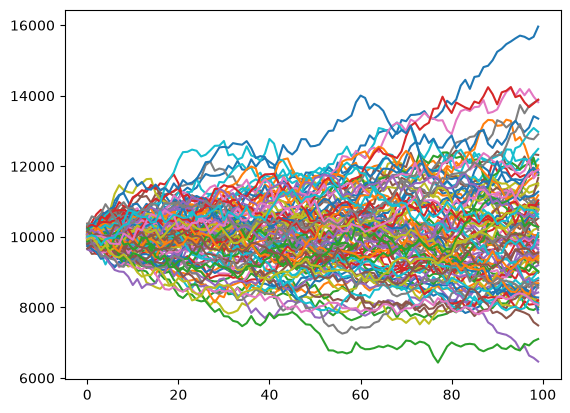

In [45]:
plt.plot(portfolio_sims)
plt.show()